## Ejercicio 10


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

from scipy.sparse import csr_matrix, issparse
from scipy.sparse.linalg import aslinearoperator, eigsh
from IPython.display import Markdown, display


### Inciso a)


In [ ]:
# Importamos la función del archivo de carga 
from cargar_datos_tomografia import cargar_datos_tomografia

In [ ]:
# Cargamos los datos y recuperamos la matriz y las mediciones
datos = cargar_datos_tomografia("datos_tomografia_final_128.npz")
A = datos["A"].astype(float)
b = datos["b"].astype(float)
n = datos["n"]

# La cantidad de ángulos es K y la cantidad de posiciones del detector es q
angulos = datos["angulos"]
posiciones_detector = datos["posiciones_detector"]
norma_ruido_esperada = datos["norma_ruido_esperada"]
K = len(angulos)
q = len(posiciones_detector)

print("Tamaño de la imagen:", n, "por", n)
print("Cantidad de ángulos K:", K)
print("Cantidad de detectores q:", q)
print("Dimensiones de A:", A.shape)
print("Dimensiones de b:", b.shape)

# Comprobamos las dimensiones de A y b
print("¿A tiene dimensiones (K*q, n^2)?", A.shape == (K * q, n**2))
print("¿b tiene K*q componentes?", b.shape == (K * q,))


Tamaño de la imagen: 128 por 128
Cantidad de ángulos K: 90
Cantidad de detectores q: 183
Dimensiones de A: (16470, 16384)
Dimensiones de b: (16470,)
¿A tiene dimensiones (K*q, n**2)? True
¿b tiene K*q componentes? True
¿A es dispersa? True
Entradas no nulas de A: 1876712
Norma esperada del ruido: 75.96688842773438


En total hay 90 ángulos y 183 posiciones de detector. Por eso, **A** tiene 16.470 filas y 16.384 columnas, y **b** tiene 16.470 componentes.

A diferencia del modelo binario, cada entrada de **A** representa la longitud del tramo de un rayo dentro de un píxel. Por eso sus valores ya no son solamente ceros y unos.


### Inciso b)


Dimensiones del sinograma: (90, 183)


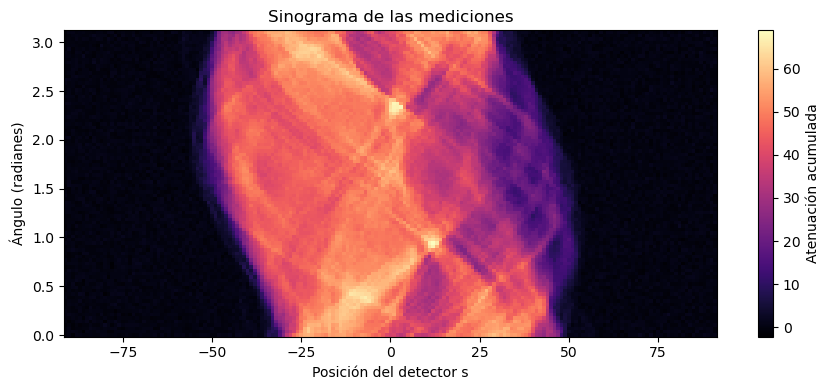

In [ ]:
# Al reorganizar b, cada fila de S corresponde a un ángulo
S = b.reshape(K, q)
print("Dimensiones del sinograma:", S.shape)

# Visualizamos el sinograma: usamos las posiciones y los ángulos de los datos como ejes 
fig, ax = plt.subplots(figsize=(9, 4))
imagen = ax.pcolormesh(posiciones_detector, angulos, S, shading="nearest", cmap="magma")
ax.set_xlabel("Posición del detector s")
ax.set_ylabel("Ángulo (radianes)")
ax.set_title("Sinograma de las mediciones")
fig.colorbar(imagen, ax=ax, label="Atenuación acumulada")
plt.tight_layout()
plt.show()


Cada fila del sinograma muestra las mediciones de un mismo ángulo, y cada columna corresponde a una posición del detector. <br> Los colores indican la atenuación acumulada medida por cada rayo.


### Inciso c)


In [ ]:
def matriz_diferencias(n):
    # Guardamos el número de fila, la columna y el valor de cada entrada no nula
    # Así construimos D sin crear antes una matriz llena de ceros
    filas = []
    columnas = []
    valores = []
    r = 0

    # Cada diferencia horizontal resta un píxel a su vecino de la derecha
    # k es la posición del píxel en el vector de la imagen
    for i in range(n):
        for j in range(n - 1):
            k = i * n + j
            filas.extend([r, r])
            columnas.extend([k, k + 1])
            valores.extend([-1.0, 1.0])
            r += 1

    # Después agregamos las diferencias con el vecino de abajo, ubicado en k + n
    for i in range(n - 1):
        for j in range(n):
            k = i * n + j
            filas.extend([r, r])
            columnas.extend([k, k + n])
            valores.extend([-1.0, 1.0])
            r += 1

    # csr_matrix arma la matriz dispersa a partir de las posiciones y los valores guardados
    dimensiones = (2 * n * (n - 1), n**2)
    D = csr_matrix((valores, (filas, columnas)), shape=dimensiones)
    return D

# Verificamos que D cumpla con las dimensiones esperadas, que se dispersa, y que cada fila tenga exactamente dos valores no nulos
D = matriz_diferencias(n)
print("Dimensiones de D:", D.shape)
print("¿Las dimensiones son las esperadas?", D.shape == (2 * n * (n - 1), n**2))
print("¿D es dispersa?", issparse(D))
print("¿Cada fila tiene dos valores no nulos?", np.all(D.getnnz(axis=1) == 2)) # getnnz(axis=1) cuenta las entradas no nulas de cada fila

Dimensiones de D: (32512, 16384)
¿Las dimensiones son las esperadas? True
¿D es dispersa? True
¿Cada fila tiene dos valores no nulos? True
Entradas no nulas de D: 65024


### Inciso d)


Usamos el método de gradiente descendiente del ejercicio 9, comenzando con una imagen de ceros. Como la reconstrucción es sin regularización tomamos $\lambda=0$.

In [ ]:
# Guardamos la traspuesta dispersa 
AT = A.T.tocsr()

# Representamos los productos con A y su traspuesta sin construir la matriz A.T @ A usando 'aslinearoperator`
operador_A = aslinearoperator(A) 
operador_H = operador_A.T @ operador_A  

valores_propios = eigsh(operador_H, k=1, which="LA", return_eigenvectors=False,
                        v0=np.ones(n**2)) # `eigsh` calcula el mayor valor propio tomando el operador_H, para luego elegir la tasa de aprendizaje

mu_max = valores_propios[0] # Tomamos el mayor autovalor y lo asignamos a mu_max

# Agregamos un margen del 1% a la estimación del mu_max
L_A = 1.01 * mu_max

print("Mayor valor propio estimado de A.T @ A:", mu_max)

Mayor valor propio estimado de A.T @ A: 11124.071666188347
Valor con margen para calcular la tasa: 11235.31238285023


Tasa de aprendizaje: 0.00016020916363193873
Iteraciones sin regularización: 20000
Motivo de parada: máximo de iteraciones


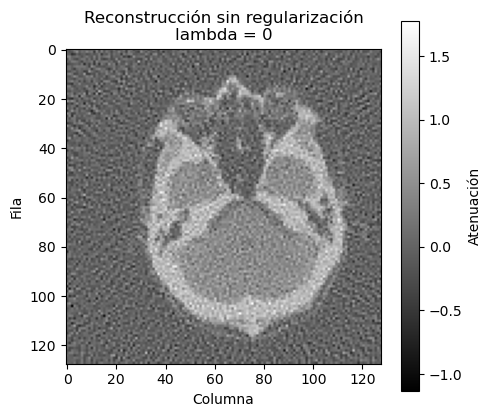

In [ ]:
def gradiente_descendiente(A, b, D, lam, alfa, max_iter=20000, tol=1e-5):
    # Empezamos con una imagen de ceros y guardamos las traspuestas (dispersas)
    x = np.zeros(A.shape[1])
    AT = A.T.tocsr()
    DT = D.T.tocsr()

    # En x=0, el gradiente es -A.T @ b. Tomamos su norma como tolerancia de parada
    norma_inicial = np.linalg.norm(AT @ b)
    costos = []
    normas_gradiente = []
    motivo = "máximo de iteraciones"
    iteraciones = 0

    for t in range(max_iter + 1):
        # Calculamos el costo y el gradiente del ajuste a las mediciones
        residuo = A @ x - b
        costo_actual = 0.5 * np.dot(residuo, residuo)
        grad = AT @ residuo

        # Si lambda no es cero, agregamos el término que penaliza diferencias entre vecinos
        if lam != 0:
            diferencias = D @ x
            costo_actual += 0.5 * lam * np.dot(diferencias, diferencias)
            grad = grad + lam * (DT @ diferencias)

        # Guardamos el costo y la norma del gradiente 
        norma_grad = np.linalg.norm(grad)
        costos.append(costo_actual)
        normas_gradiente.append(norma_grad)

        # Frenamos si aparecen valores infinitos o valores inválidos
        if not np.isfinite(costo_actual):
            motivo = "costo no finito"
            break

        # Paramos si el gradiente es suficientemente pequeño respecto del inicial
        # max(1.0, norma_inicial) evita que el umbral sea menor que 'tol'
        if norma_grad <= tol * max(1.0, norma_inicial):
            motivo = "tolerancia del gradiente"
            break

        # Si llegamos al máximo, salimos sin hacer una actualización adicional
        if t == max_iter:
            break

        x = x - alfa * grad
        iteraciones += 1

    return {"x": x, "alfa": alfa, "iteraciones": iteraciones, "motivo": motivo,
            "costos": np.array(costos), "normas_gradiente": np.array(normas_gradiente)}


# El valor 8 limita el aporte de D.T @ D a la Hessiana para esta matriz de diferencias
# Elegimos una tasa menor que 2 / (L_A + 8 * lam)
def tasa_estable(lam):
    return 1.8 / (L_A + 8 * lam)


# Calculamos la reconstrucción sin regularización y guardamos los resultados
resultados = {}
alfa = tasa_estable(0.0)
resultados[0.0] = gradiente_descendiente(A, b, D, 0.0, alfa)
x_sin_reg = resultados[0.0]["x"]

print("Tasa de aprendizaje:", alfa)
print("Iteraciones sin regularización:", resultados[0.0]["iteraciones"])
print("Motivo de parada:", resultados[0.0]["motivo"])

# Visualizamos la reconstrucción sin regularización. Reorganizamos el vector como una imagen de n por n píxeles
fig, ax = plt.subplots(figsize=(5, 5))
imagen = ax.imshow(x_sin_reg.reshape(n, n), cmap="gray")
ax.set_title("Reconstrucción sin regularización\nlambda = 0") 
ax.set_xlabel("Columna")
ax.set_ylabel("Fila")
fig.colorbar(imagen, ax=ax, label="Atenuación", shrink=0.8)
plt.tight_layout()
plt.show()


La tasa de aprendizaje depende de $\lambda$ porque la regularización modifica la Hessiana y, por lo tanto, también influye en la elección de una tasa adecuada. Para calcularla utilizamos *1.8 / (L_A + 8 * lam)*. El término *L_A* es el ajuste del 1% de la estimación del mayor autovalor, mientras que *8 * lam* contempla el aporte de la regularización. El valor 8 es una cota para el mayor autovalor de $D^TD$, que se relaciona con la cantidad de vecinos de cada píxel (como máximo, cuatro).

El criterio de parada se basa en la norma del gradiente y establece un máximo de 20.000 iteraciones. En la reconstrucción sin regularización se alcanza ese máximo, por lo que la imagen obtenida corresponde a la aproximación alcanzada hasta ese momento.

### Inciso e)


lambda: 0.1 - Iteraciones: 9942
Motivo de parada: tolerancia del gradiente

lambda: 1.0 - Iteraciones: 2423
Motivo de parada: tolerancia del gradiente

lambda: 10.0 - Iteraciones: 485
Motivo de parada: tolerancia del gradiente

lambda: 30.0 - Iteraciones: 254
Motivo de parada: tolerancia del gradiente

lambda: 100.0 - Iteraciones: 160
Motivo de parada: tolerancia del gradiente



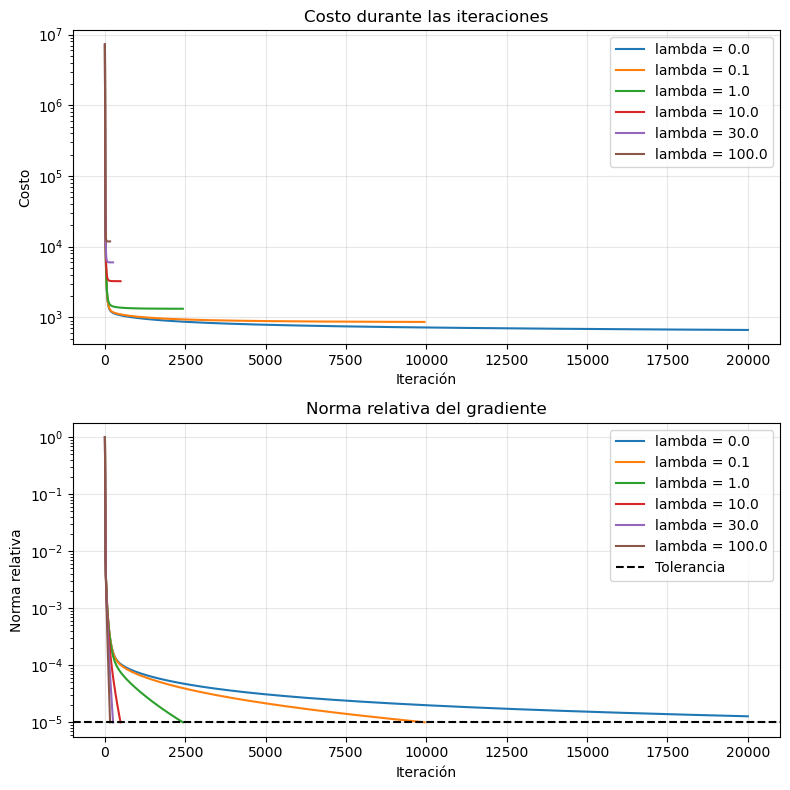

In [ ]:
# Repetimos el cálculo para los cinco valores de lambda pedidos
lambdas = [0.1, 1.0, 10.0, 30.0, 100.0]
for lam in lambdas:
    alfa = tasa_estable(lam)
    resultado = gradiente_descendiente(A, b, D, lam, alfa)
    resultados[lam] = resultado

    print("lambda:", lam, "/ Iteraciones:", resultado["iteraciones"])
    print("Motivo de parada:", resultado["motivo"])
    print()

# Incluimos también la reconstrucción sin regularización en los gráficos y la tabla
lambdas_todos = [0.0] + lambdas
norma_inicial = np.linalg.norm(AT @ b)
fig, axs = plt.subplots(2, 1, figsize=(8, 8))

for lam in lambdas_todos:
    resultado = resultados[lam]
    etiqueta = "lambda = " + str(lam)

    # Cada curva de costo corresponde al problema definido por ese lambda
    axs[0].semilogy(resultado["costos"], label=etiqueta)

    # Dividimos por la norma inicial para mostrar cuánto se redujo el gradiente.
    normas_relativas = resultado["normas_gradiente"] / max(1.0, norma_inicial)
    axs[1].semilogy(normas_relativas, label=etiqueta)

axs[0].set_title("Costo durante las iteraciones")
axs[0].set_ylabel("Costo")
axs[1].set_title("Norma relativa del gradiente")
axs[1].set_ylabel("Norma relativa")

# La línea horizontal indica la tolerancia utilizada para detener el método
axs[1].axhline(1e-5, color="black", linestyle="--", label="Tolerancia")
for i in range(2):
    axs[i].set_xlabel("Iteración")
    axs[i].legend()
    axs[i].grid(alfa=0.3)

plt.tight_layout()
plt.show()


Durante las iteraciones, los costos disminuyen. La norma relativa del gradiente permite evaluar qué casos alcanzan la tolerancia establecida. En estas pruebas, se observa que, a medida que aumenta la regularización, se necesitan menos iteraciones para cumplir el criterio de parada.

Sin embargo, como el costo incluye un término de regularización que depende de $\lambda$, no es adecuado comparar directamente los costos finales para elegir la mejor reconstrucción. Por eso, también tenemos en cuenta el residuo, el nivel de ruido y las imágenes obtenidas.

### Inciso f)

Usamos **IPython.display** únicamente para mostrar la tabla con un formato legible dentro de Jupyter. Esta herramienta no interviene en los cálculos, que se realizan con NumPy y SciPy.

| lambda | Tasa | Iteraciones | Residuo | Variación | Mínimo | Máximo | Motivo de parada |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0.0 | 0.00016021 | 20000 | 36.4 | 68.667 | -1.137 | 1.776 | máximo de iteraciones |
| 0.1 | 0.0001602 | 9942 | 39.059 | 44.137 | -0.627 | 1.502 | tolerancia del gradiente |
| 1.0 | 0.0001601 | 2423 | 44.662 | 25.475 | -0.279 | 1.207 | tolerancia del gradiente |
| 10.0 | 0.00015908 | 485 | 55.439 | 18.484 | -0.15 | 1.107 | tolerancia del gradiente |
| 30.0 | 0.00015686 | 254 | 71.606 | 15.11 | -0.104 | 1.076 | tolerancia del gradiente |
| 100.0 | 0.00014956 | 160 | 102.71 | 11.462 | -0.063 | 1.051 | tolerancia del gradiente |


Norma esperada del ruido: 75.96688842773438


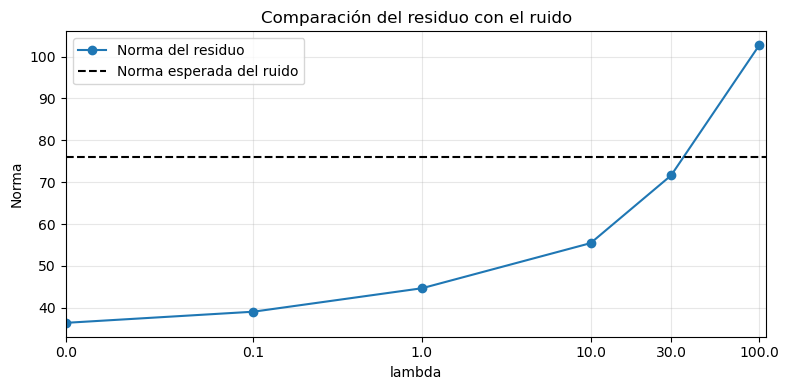

In [ ]:
# Guardamos las medidas de cada reconstrucción y preparamos la tabla.
resumen = {}
tabla_resultados = "| lambda | Tasa | Iteraciones | Residuo | Variación | Mínimo | Máximo | Motivo de parada |\n"
tabla_resultados += "| --- | --- | --- | --- | --- | --- | --- | --- |\n"
residuos = []

for lam in lambdas_todos:
    resultado = resultados[lam]
    x = resultado["x"]

    # El residuo mide el ajuste a las mediciones; la variación mide las diferencias entre vecinos.
    residuo = np.linalg.norm(A @ x - b)
    variacion = np.linalg.norm(D @ x)
    minimo = np.min(x)
    maximo = np.max(x)
    residuos.append(residuo)
    resumen[lam] = {"residuo": residuo, "variacion": variacion,
                    "minimo": minimo, "maximo": maximo}

    # Redondeamos solo los valores que mostramos, sin cambiar los resultados guardados.
    fila = [lam, round(resultado["alfa"], 8), resultado["iteraciones"],
            round(residuo, 3), round(variacion, 3), round(minimo, 3), round(maximo, 3),
            resultado["motivo"]]
    for valor in fila:
        tabla_resultados += "| " + str(valor) + " "
    tabla_resultados += "|\n"

display(Markdown(tabla_resultados))
print("Norma esperada del ruido:", norma_ruido_esperada)

# Comparamos el residuo de cada reconstrucción con la estimación del ruido.
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lambdas_todos, residuos, "o-", label="Norma del residuo")
ax.axhline(norma_ruido_esperada, linestyle="--", color="black", label="Norma esperada del ruido")

# Esta escala permite incluir lambda=0 y distinguir también los valores pequeños.
ax.set_xscale("symlog", linthresh=0.1)
ax.set_xlim(0, max(lambdas_todos) * 1.1)
ax.set_xticks(lambdas_todos)
# Las etiquetas del eje deben ser textos.
etiquetas_lambda = []
for lam in lambdas_todos:
    etiquetas_lambda.append(str(lam))
ax.set_xticklabels(etiquetas_lambda)
ax.set_xlabel("lambda")
ax.set_ylabel("Norma")
ax.set_title("Comparación del residuo con el ruido")
ax.legend()
ax.grid(alfa=0.3)
plt.tight_layout()
plt.show()


### Inciso g)


lambda elegido: 30.0
Norma del residuo: 71.6056036450258
Norma esperada del ruido: 75.96688842773438
Norma de las diferencias: 15.10987623907257


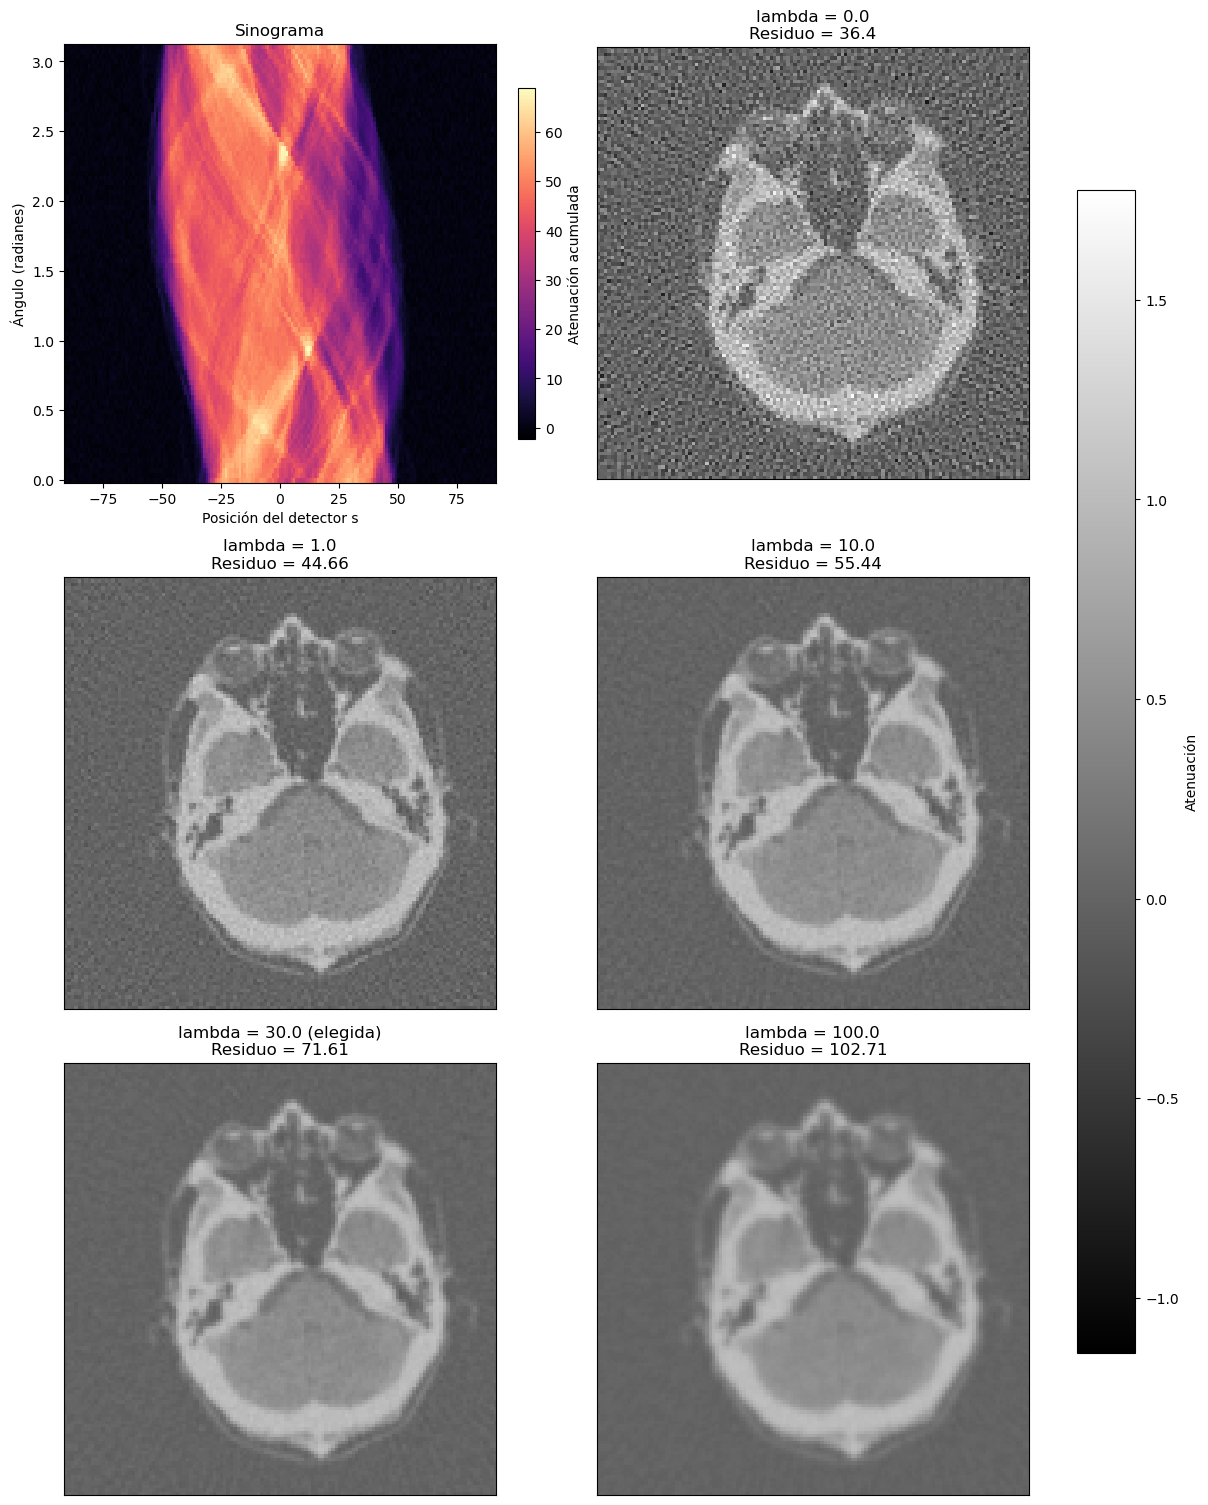

In [10]:
# Elegimos, entre los casos probados, el residuo más cercano a la norma esperada del ruido.
lambda_elegido = lambdas_todos[0]
diferencia_menor = abs(resumen[lambda_elegido]["residuo"] - norma_ruido_esperada)

for lam in lambdas_todos:
    diferencia = abs(resumen[lam]["residuo"] - norma_ruido_esperada)
    if diferencia < diferencia_menor:
        lambda_elegido = lam
        diferencia_menor = diferencia

print("lambda elegido:", lambda_elegido)
print("Norma del residuo:", resumen[lambda_elegido]["residuo"])
print("Norma esperada del ruido:", norma_ruido_esperada)
print("Norma de las diferencias:", resumen[lambda_elegido]["variacion"])

# Comparamos el caso sin regularización y cuatro reconstrucciones regularizadas.
mostrar = [0.0, 1.0, 10.0, 30.0, 100.0]
vmin = np.min(resultados[mostrar[0]]["x"])
vmax = np.max(resultados[mostrar[0]]["x"])
for lam in mostrar:
    x = resultados[lam]["x"]
    vmin = min(vmin, np.min(x))
    vmax = max(vmax, np.max(x))

# Organizamos los seis gráficos de a dos por fila.
# reshape(-1) permite recorrer los paneles con un solo índice.
fig, axs = plt.subplots(3, 2, figsize=(12, 15), layout="constrained")
axs = axs.reshape(-1)

# El primer panel es el sinograma, que tiene su propia escala de atenuación acumulada.
imagen_sinograma = axs[0].pcolormesh(posiciones_detector, angulos, S,
                                    shading="nearest", cmap="magma")
axs[0].set_title("Sinograma")
axs[0].set_xlabel("Posición del detector s")
axs[0].set_ylabel("Ángulo (radianes)")
fig.colorbar(imagen_sinograma, ax=axs[0], label="Atenuación acumulada", shrink=0.8)

for i in range(len(mostrar)):
    lam = mostrar[i]
    imagen = resultados[lam]["x"].reshape(n, n)
    ax = axs[i + 1]
    ax.imshow(imagen, cmap="gray", vmin=vmin, vmax=vmax)

    # Marcamos la reconstrucción elegida y mostramos su residuo.
    titulo = "lambda = " + str(lam)
    if lam == lambda_elegido:
        titulo += " (elegida)"
    titulo += "\nResiduo = " + str(round(resumen[lam]["residuo"], 2))
    ax.set_title(titulo)
    ax.set_xticks([])
    ax.set_yticks([])

# Todas las reconstrucciones usan los mismos límites y una barra de color común.
fig.colorbar(axs[1].images[0], ax=axs[1:], label="Atenuación", shrink=0.8)
plt.show()


Elegimos `lambda = 30`. Su residuo es aproximadamente 71,6, cercano a la norma esperada del ruido, que es 76,0. Además, la imagen conserva las estructuras principales y sus bordes, con menos oscilaciones que los casos sin regularización o con `lambda = 1`.

Sin regularización, el residuo es menor, pero la imagen presenta más variaciones en el fondo y dentro de las regiones. Esto sugiere que también se está ajustando parte del ruido. Con `lambda = 10` todavía se observa más textura que con `lambda = 30`. Con `lambda = 100`, el residuo supera la estimación del ruido y se pierden detalles por el suavizado.

La elección combina el residuo y la inspección de las imágenes con una escala común. Como no conocemos la imagen original, no podemos calcular el error real ni asegurar que este sea el mejor valor posible de `lambda`.
